#Analyze Customer Feedback

In this exercise, we analyze customer feedback using spaCy and TextBlob.

#Exercise #1:  Install Libraries and Modules



In [7]:
#Install Libraries and Modules
!pip install spacy
!pip install textblob
!pip install pandas
!pip install csv




Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 23.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 23.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 23.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable


ERROR: Could not find a version that satisfies the requirement csv (from versions: none)
ERROR: No matching distribution found for csv

[notice] A new release of pip is available: 23.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


#Exercise #2: Read in Feedback File and Create Output File for Results

In [45]:
# EXERCISE - SCROLL DOWN TO THE "START HERE" SECTION BELOW.

import spacy
from textblob import TextBlob
import pandas as pd
import csv

# Load the English NLP model
nlp = spacy.load("en_core_web_sm")


#Define the path to the file containing feedback
file_path = 'feedback_data.csv'

# Read the file using open() with the specified parameters
with open(file_path, "r", encoding="utf-8") as file:
    # Step 2: Read the lines of the file
    feedback_data = file.readlines()

# Add code to output feedback results to a file.
output_csv_path = "feedback_analysis_results.csv"

# Prepare CSV header
csv_header = ["Feedback Index", "Sentiment Polarity", "Sentiment Subjectivity", "Named Entities", "Preferred Contact Method"]

# Open CSV file for writing
with open(output_csv_path, "w", newline="", encoding="utf-8") as csv_file:
    # Create CSV writer
    csv_writer = csv.writer(csv_file)

    # Write the header
    csv_writer.writerow(csv_header)

#-----------------------------------------------------------------
# START HERE


# Initialization
token_lists = []
filtered_token_lists = []
pos_tag_lists = []
entities_lists = []

sentiment_polarity_list = []
sentiment_subjectivity_list = []

# Process and analyze each feedback
for feedback in feedback_data:
    doc = nlp(feedback.strip())

    # Tokenization
    tokens = [token.text for token in doc]
    token_lists.append(tokens)

    #Stop word removal
    filtered_tokens = [token.text for token in doc if not token.is_stop]
    filtered_token_lists.append(filtered_tokens)

    #part of speech taging
    pos_tags = [[token.text, token.pos_] for token in doc]
    pos_tag_lists.append(pos_tags)

    # Process the narrative using spaCy
    

    # Perform sentiment analysis using TextBlob
    sentiment = TextBlob(feedback.strip())
    sentiment_polarity_list.append(sentiment.polarity)
    sentiment_subjectivity_list.append(sentiment.subjectivity)

    # Extract named entities
    ner = [[ent.text, ent.label_] for ent in doc.ents]
    entities_lists.append(ner)


with open(output_csv_path, "a", newline="", encoding="utf-8") as csv_file:
    csv_writer = csv.writer(csv_file)

    for idx, narrative in enumerate(feedback_data):
        # Determine the preferred contact method
        preferred_contact_method = "chat" if "email" not in narrative.lower() else "email"
        print(f"Preferred Contact Method: {preferred_contact_method}")

        sentiment_polarity = sentiment_polarity_list[idx]
        sentiment_subjectivity = sentiment_subjectivity_list[idx]

        # Write the results to the CSV file
        csv_writer.writerow([idx, sentiment_polarity, sentiment_subjectivity, entities_lists[idx], preferred_contact_method])

#-----------------------------------------------------------------

Preferred Contact Method: email
Preferred Contact Method: email
Preferred Contact Method: chat
Preferred Contact Method: email


#Exercise #3:  Exploratory Data Analysis on Customer Feedback

In [46]:
##Load results file into a Pandas Dataframe
df = pd.read_csv('feedback_analysis_results.csv')

# Display the first rows of the DataFrame
print(df.head)


<bound method NDFrame.head of    Feedback Index  Sentiment Polarity  Sentiment Subjectivity  \
0               0            0.441667                0.666667   
1               1            0.136364                0.454545   
2               2            0.484091                0.751136   
3               3           -0.750000                0.750000   

               Named Entities Preferred Contact Method  
0    [['Los Angeles', 'GPE']]                    email  
1       [['New York', 'GPE']]                    email  
2  [['San Francisco', 'GPE']]                     chat  
3        [['Chicago', 'GPE']]                    email  >


In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Feedback         4 non-null      object
 1   Tokens           4 non-null      object
 2   Filtered Tokens  4 non-null      object
 3   POS Tags         4 non-null      object
 4   Named Entities   4 non-null      object
dtypes: object(5)
memory usage: 288.0+ bytes


##Plot the Preferred Contact Method

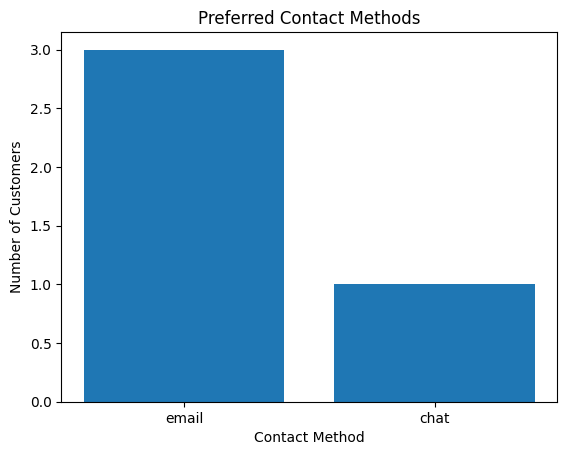

In [36]:
# Example plot: Preferred Contact Method Count
import matplotlib.pyplot as plt

df = pd.read_csv(output_csv_path)
contact_counts = df["Preferred Contact Method"].value_counts()

plt.bar(contact_counts.index, contact_counts.values)
plt.xlabel("Contact Method")
plt.ylabel("Number of Customers")
plt.title("Preferred Contact Methods")

plt.show()


##Plot the Sentiment Polarity and Sentiment Subjectivity

In [38]:
!pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
     ---------------------------------------- 0.0/294.9 kB ? eta -:--:--
     ---- ----------------------------------- 30.7/294.9 kB ? eta -:--:--
     ---------- ---------------------------- 81.9/294.9 kB 1.1 MB/s eta 0:00:01
     ------------- ---------------------- 112.6/294.9 kB 930.9 kB/s eta 0:00:01
     -------------------------- ----------- 204.8/294.9 kB 1.6 MB/s eta 0:00:01
     ------------------------------- ------ 245.8/294.9 kB 1.7 MB/s eta 0:00:01
     -------------------------------------- 294.9/294.9 kB 1.4 MB/s eta 0:00:00



[notice] A new release of pip is available: 23.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


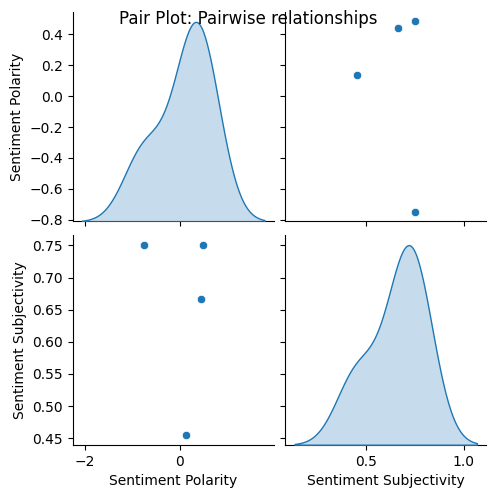

In [39]:
import seaborn as sns
# Pair Plot: Pairwise relationships
sns.pairplot(data=df[['Sentiment Polarity', 'Sentiment Subjectivity']],
             diag_kind='kde')
plt.suptitle('Pair Plot: Pairwise relationships')
plt.show()